# Māori Data Classification and Confidence Analysis

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!pip install google-genai

In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
MODEL = "gemini-3-flash-preview"

In [ ]:
DATA_PATH = "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/HuggingFace_Dataset"

In [ ]:
from datasets import load_from_disk

hf_dataset_filtered = load_from_disk(DATA_PATH)

print(hf_dataset_filtered)

Dataset({
    features: ['title', 'authors', 'year', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count'],
    num_rows: 16589
})


In [ ]:
import time
import json
from datasets import load_from_disk, DatasetDict
from google import genai
from google.genai import types

client = genai.Client(
    vertexai=True,
    project="gen-lang-client-0900489206",
    location="global"
)

In [ ]:
def classify_prompt(prompt, model=MODEL, temperature=0.0):
    response = client.models.generate_content(
        model=model,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=temperature,
            response_mime_type="application/json",
        ),
    )
    try:
        result = json.loads(response.text)
        if isinstance(result, list) and len(result) > 0:
            result = result[0]
        if isinstance(result, dict):
            return result
        else:
            print(f"[WARN] Model returned non-dict JSON: {response.text}")
            return None
    except json.JSONDecodeError as e:
        print(f"[WARN] Failed to decode JSON: {e} - Response text: {response.text}")
        return None

def classify_with_retry(prompt, model=MODEL):
    backoff = [30, 60, 60]
    for i in range(3):
        try:
            return classify_prompt(prompt, model=model)
        except Exception as e:
            msg = str(e).lower()
            if i < 2:
                wait = backoff[i]
                if any(x in msg for x in ["quota", "resource exhausted", "503", "429", "unavailable"]):
                    print(f"[WARN] quota hit → sleeping {wait}s")
                else:
                    print(f"[WARN] api error → sleeping {wait}s | {e}")
                time.sleep(wait)
            else:
                print("[ERROR] failed permanently")
                return None

In [ ]:
def classify_prompt(prompt, model=MODEL, temperature=0.0):
    response = client.models.generate_content(
        model=model,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=temperature,
            response_mime_type="application/json",
        ),
    )
    try:
        result = json.loads(response.text)
        if isinstance(result, list) and len(result) > 0:
            result = result[0]
        if isinstance(result, dict):
            return result
        else:
            print(f"[WARN] Model returned non-dict JSON: {response.text}")
            return None
    except json.JSONDecodeError as e:
        print(f"[WARN] Failed to decode JSON: {e} - Response text: {response.text}")
        return None

def classify_with_retry(prompt, model=MODEL):
    backoff = [30, 60, 60]
    for i in range(3):
        try:
            return classify_prompt(prompt, model=model)
        except Exception as e:
            msg = str(e).lower()
            if i < 2:
                wait = backoff[i]
                if any(x in msg for x in ["quota", "resource exhausted", "503", "429", "unavailable"]):
                    print(f"[WARN] quota hit → sleeping {wait}s")
                else:
                    print(f"[WARN] api error → sleeping {wait}s | {e}")
                time.sleep(wait)
            else:
                print("[ERROR] failed permanently")
                return None

In [ ]:
def worker(queue, results, requests_per_min=60):
    sleep_per_request = 60 / requests_per_min

    while not queue.empty():
        try:
            idx, prompt = queue.get_nowait()
        except:
            break

        result = classify_with_retry(prompt)

        if result is None:
            output = ("non_maori_origin", 0.0, "failed")
        else:
            output = (
                result.get("label", "non_maori_origin"),
                result.get("confidence", 0.0),
                result.get("reason", "")
            )

        results[idx] = output

        time.sleep(sleep_per_request)
        queue.task_done()

In [ ]:
import threading
import time
import json
import os
import queue # Explicitly import the queue module
from tqdm.notebook import tqdm # Import tqdm for progress bar

def classify_parallel(dataset, num_workers=3, checkpoint_path=None, save_interval=100):

    task_queue = queue.Queue() # Rename queue variable to task_queue
    results = {}
    processed_count = 0 # Track processed items for periodic saving
    save_lock = threading.Lock() # Lock for thread-safe checkpoint saving

    # Load existing results from checkpoint if available
    if checkpoint_path and os.path.exists(checkpoint_path):
        try:
            with open(checkpoint_path, 'r') as f:
                loaded_results = json.load(f)
            # Ensure keys are int and values are tuples
            results = {int(k): tuple(v) for k, v in loaded_results.items()}
            processed_count = len(results) # Update processed_count based on loaded results
            print(f"Loaded {processed_count} previously classified items from checkpoint: {checkpoint_path}")
        except json.JSONDecodeError as e:
            print(f"[WARN] Failed to load checkpoint: {e}. Starting fresh.")
            results = {} # Reset results if checkpoint is corrupted
        except Exception as e:
            print(f"[WARN] An unexpected error occurred while loading checkpoint: {e}. Starting fresh.")
            results = {} # Reset results if loading fails

    initial_prompts_to_process = []
    for i, prompt in enumerate(dataset["prompt"]):
        if i not in results:
            initial_prompts_to_process.append((i, prompt))

    # load jobs with a progress bar, only for items not yet in results
    for i, prompt in tqdm(initial_prompts_to_process, total=len(initial_prompts_to_process), desc="Loading remaining prompts to queue"):
        task_queue.put((i, prompt))

    threads = []

    # Initialize tqdm with initial_prompts_to_process count, which is the number of new items to classify
    progress_bar = tqdm(total=len(initial_prompts_to_process), desc="Classifying prompts")

    def worker_with_progress(task_queue, results, progress_bar, requests_per_min, model_name, save_lock):
        nonlocal processed_count # Declare processed_count as nonlocal to modify it
        sleep_per_request = 60 / requests_per_min

        while True:
            # Get an item from the queue; block until one is available.
            # If a None sentinel is received, it's a signal to terminate.
            item = task_queue.get()

            if item is None:
                task_queue.task_done() # Mark the sentinel as done
                break # Exit the worker loop

            idx, prompt = item # Unpack the actual task

            result = classify_with_retry(prompt, model=model_name)

            if result is None or not isinstance(result, dict):
                output = ("non_maori_origin", 0.0, "failed")
            else:
                output = (
                    result.get("label", "non_maori_origin"),
                    result.get("confidence", 0.0),
                    result.get("reason", "")
                )

            with save_lock: # Protect access to results and processed_count
                results[idx] = output
                processed_count += 1

                # Periodic checkpoint save
                if checkpoint_path and processed_count % save_interval == 0:
                    serializable_results = {str(k): list(v) for k, v in results.items()}
                    with open(checkpoint_path, 'w') as f:
                        json.dump(serializable_results, f, indent=4)
                    print(f"[INFO] Checkpoint saved at {processed_count} items.")

            progress_bar.update(1)
            task_queue.task_done() # Mark this task as done

            time.sleep(sleep_per_request)

    for _ in range(num_workers):
        t = threading.Thread(target=worker_with_progress, args=(task_queue, results, progress_bar, 60, MODEL, save_lock))
        t.start()
        threads.append(t)

    # Wait for all tasks in the queue to be completed by workers
    task_queue.join()

    # Once all tasks are done, signal workers to terminate gracefully
    for _ in range(num_workers):
        task_queue.put(None) # Add a sentinel value for each worker

    # Wait for all worker threads to actually terminate
    for t in threads:
        t.join()

    progress_bar.close()

    # Final save after all threads are done
    if checkpoint_path:
        serializable_results = {str(k): list(v) for k, v in results.items()}
        with open(checkpoint_path, 'w') as f:
            json.dump(serializable_results, f, indent=4)
        print(f"Final checkpoint saved to {checkpoint_path}")

    # reconstruct dataset outputs
    labels = []
    confidences = []
    reasons = []

    for i in range(len(dataset)):
        label, conf, reason = results.get(i, ("non_maori_origin", 0.0, "not_processed_or_failed_checkpoint_load"))
        labels.append(label)
        confidences.append(conf)
        reasons.append(reason)

    return dataset.add_column("classification_label", labels) \
                  .add_column("classification_confidence", confidences) \
                  .add_column("classification_reason", reasons)

In [ ]:
import queue
from threading import Thread # Also importing Thread for robustness, as it's used in classify_parallel

hf_dataset_filtered = classify_parallel(
    hf_dataset_filtered,
    num_workers=5,
    checkpoint_path="/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/classification_checkpoint.json" # Add checkpoint path
)

Loaded 16500 previously classified items from checkpoint: /content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/classification_checkpoint.json


Loading remaining prompts to queue:   0%|          | 0/89 [00:00<?, ?it/s]

Classifying prompts:   0%|          | 0/89 [00:00<?, ?it/s]

Final checkpoint saved to /content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/stage2_colab/classification_checkpoint.json


In [ ]:
print(f"Total count of items in the dataset: {len(hf_dataset_filtered)}")

Total count of items in the dataset: 16589


In [ ]:
display(hf_dataset_filtered.to_pandas().head())

,title,authors,year,subjects,abstract,text,record_id_hash,prompt,token_count,classification_label,classification_confidence,classification_reason
0,Characterizing porous microaggregates and soil...,"Huang, Doreen Yu-Tuan",2021,Science & Technology,Allophanic tephra-derived soils can sequester ...,Characterizing porous microaggregates and soil...,fefa3d488de2a37e6bac3bb97033e389a7f3274f1626b8...,You are a specialist in classifying academic r...,1291,non_maori_origin,1.00,The research is a technical soil science study...
1,Sexual Desire in Women Presenting for Antiandr...,"Conaglen, Helen M.",2003,antiandrogen therapy,Women presenting with hirsuties/polycystic ova...,Sexual Desire in Women Presenting for Antiandr...,7e6086aed791d4d7c9e56b862f4a36aaaf39e6f0de8d15...,You are a specialist in classifying academic r...,1167,non_maori_origin,1.00,The research is a clinical medical study focus...
2,Aluminium content in near-shore sediments of L...,"Tempero, Grant Wayne",2019,None,The application of alum (aluminium sulphate) i...,Aluminium content in near-shore sediments of L...,b9b3e816cb791407640fa08a033bc2b7b09c4fb9a7438c...,You are a specialist in classifying academic r...,1146,non_maori_origin,0.90,The research is a technical environmental scie...
3,Introduction,"Houlahan, Mark",2019,None,"When Dr Johnson, the 18• century critic, was a...","Introduction When Dr Johnson, the 18• century ...",4c3bde78419fd2dcf4944c39180e42d828f641c5ac05a8...,You are a specialist in classifying academic r...,974,non_maori_origin,0.95,The research paper is an introduction to an an...
4,Is peer review in academic publishing still wo...,"Jackson, Liz",2018,Peer review,Peer review is central to academic publishing....,Is peer review in academic publishing still wo...,85ee578de741354f56d5fae8970ad2c89319d64b6efdce...,You are a specialist in classifying academic r...,991,non_maori_origin,1.00,The research paper focuses on the general acad...


In [ ]:
print(hf_dataset_filtered.to_pandas()['classification_label'].value_counts())

classification_label
non_maori_origin    14753
maori_origin         1836
Name: count, dtype: int64


In [ ]:
hf_dataset_filtered.to_pandas().info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16589 entries, 0 to 16588
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   title                      16589 non-null  object 
 1   authors                    16589 non-null  object 
 2   year                       16589 non-null  object 
 3   subjects                   11930 non-null  object 
 4   abstract                   16589 non-null  object 
 5   text                       16589 non-null  object 
 6   record_id_hash             16589 non-null  object 
 7   prompt                     16589 non-null  object 
 8   token_count                16589 non-null  int64  
 9   classification_label       16589 non-null  object 
 10  classification_confidence  16589 non-null  float64
 11  classification_reason      16589 non-null  object 
dtypes: float64(1), int64(1), object(10)
memory usage: 1.5+ MB


## Splitting the Dataset into Train and Test Sets

In [ ]:
from datasets import Features, Value, ClassLabel

features = Features({
    "title": Value("string"),
    "authors": Value("string"),
    "subjects": Value("string"),
    "abstract": Value("string"),
    "text": Value("string"),
    "record_id_hash": Value("string"),
    "prompt": Value("string"),
    "token_count": Value("int32"),
    "classification_label": Value("string"),  # temp, will convert later
    "classification_reason": Value("string"),
    "year": Value("string"),
    "classification_confidence": Value("float32"),
})

hf_dataset_filtered = hf_dataset_filtered.cast(features)

In [ ]:
hf_dataset_filtered.to_pandas().info()

In [ ]:
labels = sorted(set(hf_dataset_filtered["classification_label"]))

In [ ]:
class_label_feature = ClassLabel(names=labels)

In [ ]:
def encode_label(example):
    example["classification_label"] = class_label_feature.str2int(
        example["classification_label"]
    )
    return example

hf_dataset_filtered = hf_dataset_filtered.map(encode_label)

In [ ]:
features["classification_label"] = class_label_feature
hf_dataset_filtered = hf_dataset_filtered.cast(features)

Casting the dataset:   0%|          | 0/16589 [00:00<?, ? examples/s]

In [ ]:
dataset_dict = hf_dataset_filtered.train_test_split(
    test_size=0.2,
    stratify_by_column="classification_label",
    seed=42,
)

In [ ]:
dataset_dict["train"]
dataset_dict["test"]

Dataset({
    features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence'],
    num_rows: 3318
})

In [ ]:
from collections import Counter

print("Train:", Counter(dataset_dict["train"]["classification_label"]))
print("Test:", Counter(dataset_dict["test"]["classification_label"]))

Train: Counter({1: 11802, 0: 1469})
Test: Counter({1: 2951, 0: 367})


In [ ]:
from huggingface_hub import login
from google.colab import userdata

# Retrieve the HF_TOKEN from Colab's Secrets Manager
HF_TOKEN = userdata.get('HF_TOKEN')
login(token=HF_TOKEN)

In [ ]:
dataset_dict.push_to_hub("dinushiTJ/nz_research_commons_classification")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/14 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  32%|###1      | 3.86MB / 12.1MB            

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_research_commons_classification/commit/4616992b1f42508a575b6bac93e3acef69569f32', commit_message='Upload dataset', commit_description='', oid='4616992b1f42508a575b6bac93e3acef69569f32', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_research_commons_classification', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_research_commons_classification'), pr_revision=None, pr_num=None)

### Fixing Low Confidence Rows and Re-uploading
We will identify the indices in both `train` and `test` sets that have a confidence of 0.0 and re-run the classification for them.

In [ ]:
def reclassify_failed_rows(ds):
    failed_indices = [i for i, conf in enumerate(ds['classification_confidence']) if conf == 0.0]
    if not failed_indices:
        print("No rows found with 0.0 confidence.")
        return ds
    print(f"Found {len(failed_indices)} rows to re-classify.")
    def apply_fix(example, idx):
        if idx in failed_indices:
            print(f"Re-classifying index {idx}...")
            # Ensure MODEL is passed correctly
            result = classify_with_retry(example['prompt'], model=MODEL)
            if result and isinstance(result, dict):
                label_str = result.get("label", "non_maori_origin")
                example['classification_label'] = class_label_feature.str2int(label_str)
                example['classification_confidence'] = float(result.get("confidence", 0.0))
                example['classification_reason'] = result.get("reason", "fixed via sequential retry")
            else:
                print(f"[WARN] Sequential re-classification failed again at index {idx}")
        return example
    return ds.map(apply_fix, with_indices=True)

print("Processing Train set...")
dataset_dict['train'] = reclassify_failed_rows(dataset_dict['train'])
print("\nProcessing Test set...")
dataset_dict['test'] = reclassify_failed_rows(dataset_dict['test'])
train_zeros = sum(1 for c in dataset_dict['train']['classification_confidence'] if c == 0.0)
test_zeros = sum(1 for c in dataset_dict['test']['classification_confidence'] if c == 0.0)
print(f"\nRemaining rows with 0.0 confidence - Train: {train_zeros}, Test: {test_zeros}")

Processing Train set...
Found 2 rows to re-classify.


Map:   0%|          | 0/13271 [00:00<?, ? examples/s]

Re-classifying index 2650...
Re-classifying index 7189...

Processing Test set...
No rows found with 0.0 confidence.

Remaining rows with 0.0 confidence - Train: 0, Test: 0


In [ ]:
# Re-upload the fixed dataset to the Hub
dataset_dict.push_to_hub("dinushiTJ/nz_research_commons_classification")
print("Dataset successfully re-uploaded to Hugging Face Hub.")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/14 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  23%|##3       | 11.2MB / 47.8MB            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 12.1MB / 12.1MB            

README.md:   0%|          | 0.00/935 [00:00<?, ?B/s]

Dataset successfully re-uploaded to Hugging Face Hub.


## Confidence Analysis on Train and Test Sets

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert train and test splits to pandas DataFrames
df_train = dataset_dict['train'].to_pandas()
df_test = dataset_dict['test'].to_pandas()

# Map classification_label back to string for better readability
df_train['classification_label_str'] = df_train['classification_label'].map(class_label_feature.int2str)
df_test['classification_label_str'] = df_test['classification_label'].map(class_label_feature.int2str)

print("DataFrames for train and test sets created and labels mapped.")

DataFrames for train and test sets created and labels mapped.


### Confidence Distribution for Train Set

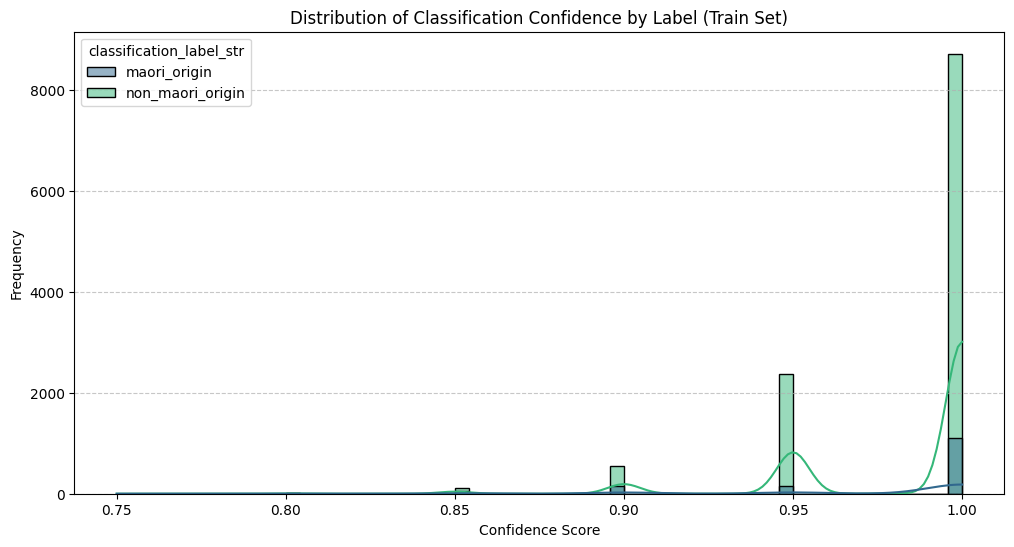

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df_train, x='classification_confidence', hue='classification_label_str', kde=True, palette='viridis')
plt.title('Distribution of Classification Confidence by Label (Train Set)')
plt.xlabel('Confidence Score')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Confidence Distribution for Test Set

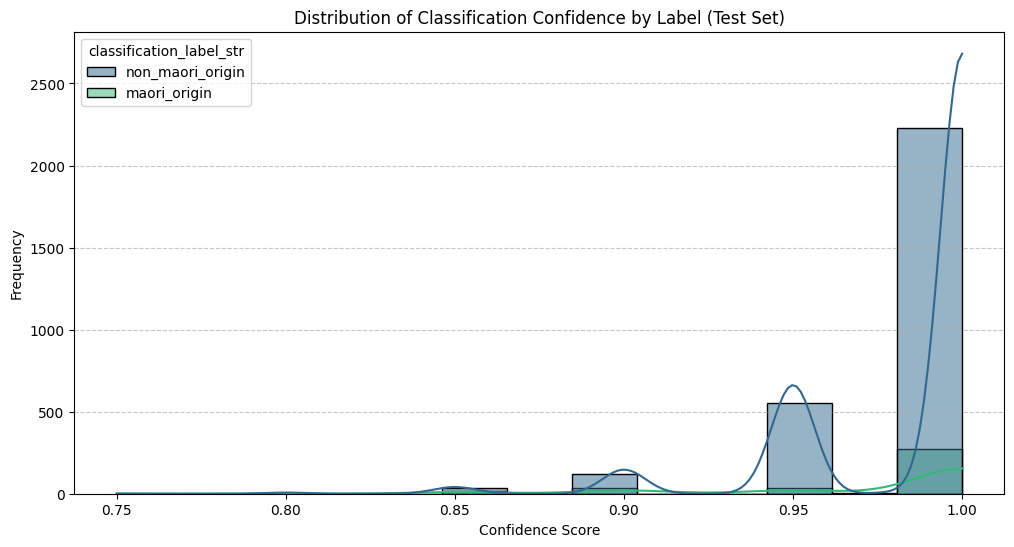

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df_test, x='classification_confidence', hue='classification_label_str', kde=True, palette='viridis')
plt.title('Distribution of Classification Confidence by Label (Test Set)')
plt.xlabel('Confidence Score')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Summary Statistics of Confidence Scores

In [ ]:
print('Summary Statistics of Confidence Scores per Class (Train Set):')
confidence_stats_train = df_train.groupby('classification_label_str')['classification_confidence'].describe()
display(confidence_stats_train)

print('\nSummary Statistics of Confidence Scores per Class (Test Set):')
confidence_stats_test = df_test.groupby('classification_label_str')['classification_confidence'].describe()
display(confidence_stats_test)

Summary Statistics of Confidence Scores per Class (Train Set):


,count,mean,std,min,25%,50%,75%,max
classification_label_str,,,,,,,,
maori_origin,1469.0,0.977883,0.043240,0.75,1.00,1.0,1.0,1.0
non_maori_origin,11802.0,0.983416,0.031395,0.75,0.95,1.0,1.0,1.0



Summary Statistics of Confidence Scores per Class (Test Set):


,count,mean,std,min,25%,50%,75%,max
classification_label_str,,,,,,,,
maori_origin,367.0,0.976785,0.044433,0.80,0.95,1.0,1.0,1.0
non_maori_origin,2951.0,0.984270,0.031554,0.75,1.00,1.0,1.0,1.0


### Examples of Low Confidence Classifications

In [ ]:
print("Low Confidence Classifications (Train Set):")
low_confidence_train = df_train[df_train['classification_confidence'] < 0.8].sort_values(by='classification_confidence', ascending=True)
print(f"Number of entries with confidence less than 0.8 in Train Set: {len(low_confidence_train)}")
display(low_confidence_train[['prompt', 'classification_label_str', 'classification_confidence', 'classification_reason']].head(10))

print("\nLow Confidence Classifications (Test Set):")
low_confidence_test = df_test[df_test['classification_confidence'] < 0.8].sort_values(by='classification_confidence', ascending=True)
print(f"Number of entries with confidence less than 0.8 in Test Set: {len(low_confidence_test)}")
display(low_confidence_test[['prompt', 'classification_label_str', 'classification_confidence', 'classification_reason']].head(10))

Low Confidence Classifications (Train Set):
Number of entries with confidence less than 0.8 in Train Set: 3


,prompt,classification_label_str,classification_confidence,classification_reason
4009,You are a specialist in classifying academic r...,maori_origin,0.75,The research excursion includes a specific foc...
4640,You are a specialist in classifying academic r...,non_maori_origin,0.75,The research focuses on a behavioral intervent...
7954,You are a specialist in classifying academic r...,maori_origin,0.75,The research identifies 'Treaty partners' (Māo...



Low Confidence Classifications (Test Set):
Number of entries with confidence less than 0.8 in Test Set: 1


,prompt,classification_label_str,classification_confidence,classification_reason
32,You are a specialist in classifying academic r...,non_maori_origin,0.75,The title and abstract indicate a general anal...


### Failed Classifications (if any)

In [ ]:
print("Failed Classifications (Train Set):")
failed_classifications_train = df_train[df_train['classification_reason'] == 'failed']
print(f"Number of failed classifications in Train Set: {len(failed_classifications_train)}")
display(failed_classifications_train[['prompt', 'classification_label_str', 'classification_confidence', 'classification_reason']].head())

print("\nFailed Classifications (Test Set):")
failed_classifications_test = df_test[df_test['classification_reason'] == 'failed']
print(f"Number of failed classifications in Test Set: {len(failed_classifications_test)}")
display(failed_classifications_test[['prompt', 'classification_label_str', 'classification_confidence', 'classification_reason']].head())

Failed Classifications (Train Set):
Number of failed classifications in Train Set: 0


,prompt,classification_label_str,classification_confidence,classification_reason



Failed Classifications (Test Set):
Number of failed classifications in Test Set: 0


,prompt,classification_label_str,classification_confidence,classification_reason
